In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

rubscores_wrongness_path = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_full_wrongness_f0p2_max8t_output_metric2.csv"#attributions_validation_wrongness_metric2_output.csv"#"/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_full_wrongness_f0p2_max8t_output.csv"
rubscores_overc_path = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_rub_scores/attributions_full_overconfidence_metric1_f0p2_max8t_output.csv"
 
w_attributions_df = pd.read_csv(rubscores_wrongness_path)
oc_attributions_df = pd.read_csv(rubscores_overc_path)

d = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/token_scores_olmo_career.npz")
df = pd.DataFrame({k: d[k] for k in d.files })



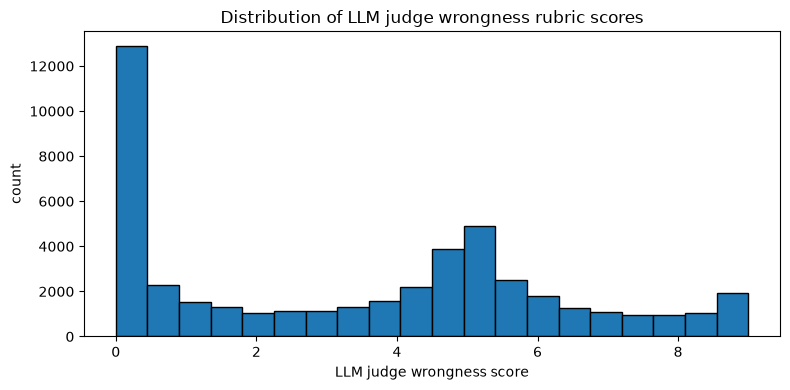

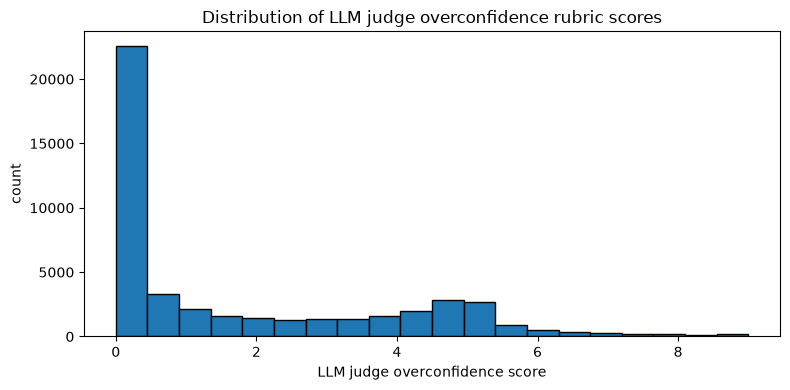

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(w_attributions_df["score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("LLM judge wrongness score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge wrongness rubric scores")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(oc_attributions_df["score"].dropna(), bins=20, edgecolor="black")
ax.set_xlabel("LLM judge overconfidence score")
ax.set_ylabel("count")
ax.set_title("Distribution of LLM judge overconfidence rubric scores")
plt.tight_layout()
plt.show()

46721/46721 rubric-scored tokens matched an IF score
Spearman r=0.077, p=3.70e-62


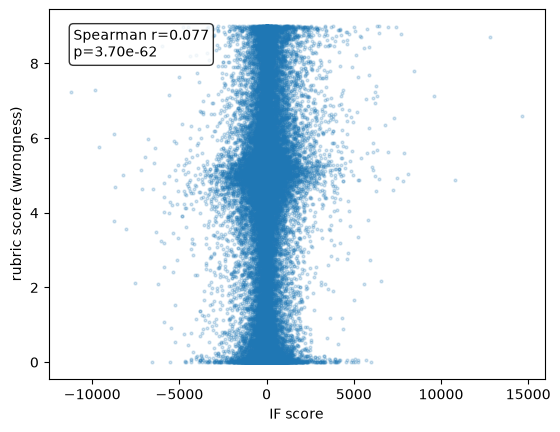

Spearman r=0.088, p=1.54e-80


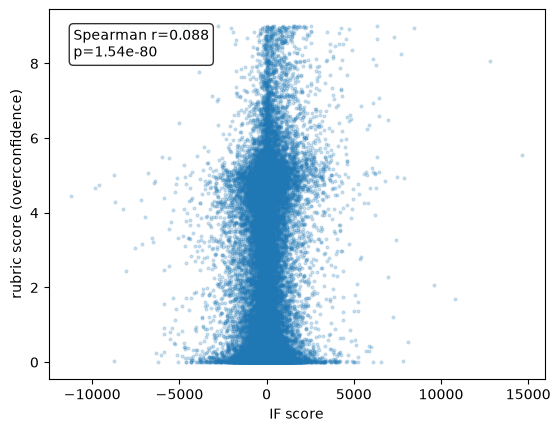

In [3]:
from scipy.stats import spearmanr
df_w_oc = w_attributions_df.merge(oc_attributions_df, on = ["example_idx", "position", "token_id", "token_text"], suffixes=["_w", "_oc"] )
#print(df_w_oc)
df_merged = df.merge(df_w_oc, on=["example_idx", "position", "token_id"])
print(f"{len(df_merged)}/{len(df_w_oc)} rubric-scored tokens matched an IF score")

sc = [("score_w", "wrongness"), ("score_oc", "overconfidence")]
for rub_score, label in sc:
    corr, pval = spearmanr(df_merged["score"], df_merged[rub_score])
    print(f"Spearman r={corr:.3f}, p={pval:.2e}")

    plt.scatter(df_merged["score"], df_merged[rub_score], s=4, alpha=0.2, rasterized=True)
    plt.xlabel("IF score")
    plt.ylabel(f"rubric score ({label})")
    plt.text(0.05, 0.95, f"Spearman r={corr:.3f}\np={pval:.2e}",
            transform=plt.gca().transAxes, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    plt.show()

46721/46721 rubric-scored tokens matched an IF score
Spearman r=0.182, p=0.00e+00


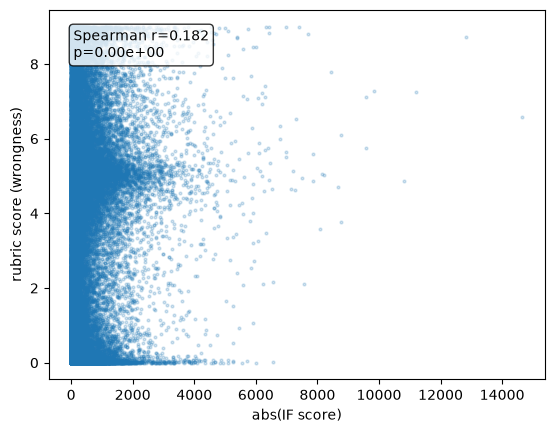

Spearman r=0.217, p=0.00e+00


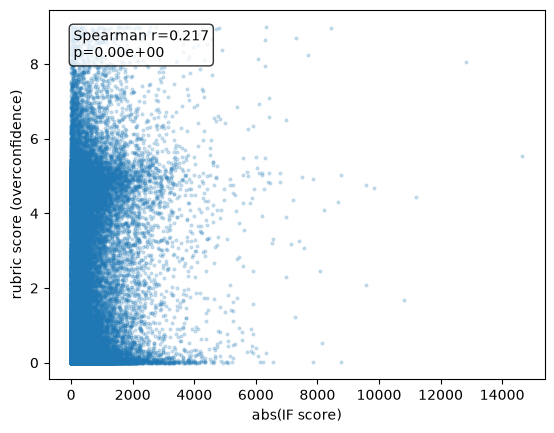

In [4]:
df_w_oc = w_attributions_df.merge(oc_attributions_df, on = ["example_idx", "position", "token_id", "token_text"], suffixes=["_w", "_oc"] )
#print(df_w_oc)
df_merged = df.merge(df_w_oc, on=["example_idx", "position", "token_id"])
print(f"{len(df_merged)}/{len(df_w_oc)} rubric-scored tokens matched an IF score")

sc = [("score_w", "wrongness"), ("score_oc", "overconfidence")]
for rub_score, label in sc:
    corr, pval = spearmanr(df_merged["score"].abs(), df_merged[rub_score])
    print(f"Spearman r={corr:.3f}, p={pval:.2e}")

    plt.scatter(df_merged["score"].abs(), df_merged[rub_score], s=4, alpha=0.2, rasterized=True)
    plt.xlabel("abs(IF score)")
    plt.ylabel(f"rubric score ({label})")
    plt.text(0.05, 0.95, f"Spearman r={corr:.3f}\np={pval:.2e}",
            transform=plt.gca().transAxes, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    plt.show()

Spearman r=0.766, p=0.00e+00


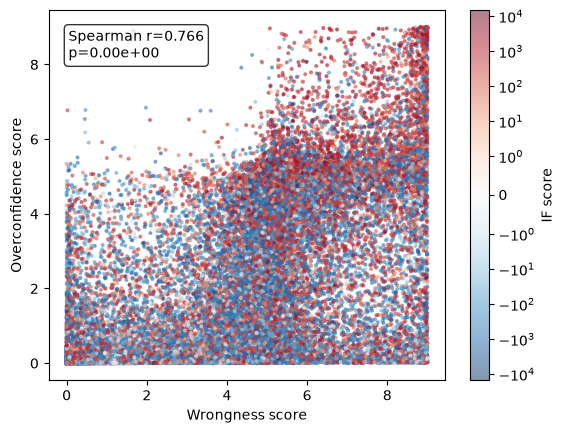

In [5]:
import matplotlib.colors as mcolors

# Symmetric log norm, not linear: IF scores are heavy-tailed (range to ~1e4),
# so a linear colormap would make everything near 0 look like one flat color.
score_vmax = df_merged["score"].abs().max()
if_norm = mcolors.SymLogNorm(linthresh=1.0, vmin=-score_vmax, vmax=score_vmax)

corr, pval = spearmanr(df_merged["score_w"], df_merged["score_oc"])
print(f"Spearman r={corr:.3f}, p={pval:.2e}")

sc = plt.scatter(df_merged["score_w"], df_merged["score_oc"], c=df_merged["score"],
                  cmap="RdBu_r", norm=if_norm, s=4, alpha=0.5, rasterized=True)
plt.colorbar(sc, label="IF score")
plt.xlabel("Wrongness score")
plt.ylabel("Overconfidence score")
plt.text(0.05, 0.95, f"Spearman r={corr:.3f}\np={pval:.2e}",
        transform=plt.gca().transAxes, va="top",
           bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.show()


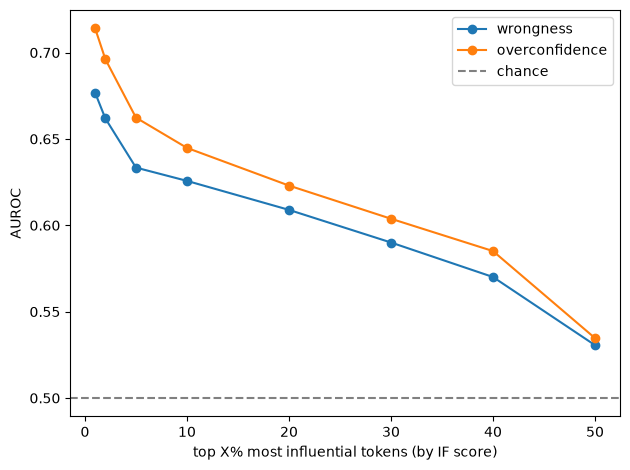

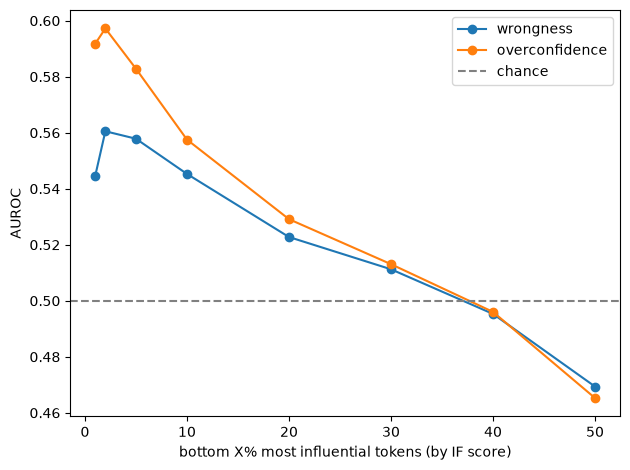

In [6]:
from scipy.stats import mannwhitneyu


def auroc_extreme_x(df, x_pct, score_col="score_rubric", if_col="score", tail="top"):
    """AUROC for score_col as a predictor of 'is this token in the top/bottom x_pct% by if_col'.
    tail="top": positive class = highest if_col (most influential in the positive direction).
    tail="bottom": positive class = lowest if_col (most influential in the negative direction).
    Computed via Mann-Whitney U (AUROC = U / (n_pos * n_neg)) to avoid needing sklearn."""
    if tail == "top":
        threshold = df[if_col].quantile(1 - x_pct / 100)
        is_extreme = (df[if_col] >= threshold).to_numpy()
    else:
        threshold = df[if_col].quantile(x_pct / 100)
        is_extreme = (df[if_col] <= threshold).to_numpy()
    pos = df.loc[is_extreme, score_col].to_numpy()
    neg = df.loc[~is_extreme, score_col].to_numpy()
    U, _ = mannwhitneyu(pos, neg, alternative="two-sided")
    return U / (len(pos) * len(neg))


def auroc_top_x(df, x_pct, score_col="score_rubric", if_col="score"):
    return auroc_extreme_x(df, x_pct, score_col=score_col, if_col=if_col, tail="top")


x_values = [1, 2, 5, 10, 20, 30, 40, 50]
rubrics = [("score_w", "wrongness"), ("score_oc", "overconfidence")]

for tail, title in [("top", "top X% most influential tokens (by IF score)"),
                     ("bottom", "bottom X% most influential tokens (by IF score)")]:
    for score_col, label in rubrics:
        aurocs = [auroc_extreme_x(df_merged, x, score_col=score_col, tail=tail) for x in x_values]
    
        plt.plot(x_values, aurocs, marker="o", label=label)

    plt.axhline(0.5, color="gray", linestyle="--", label="chance")
    plt.xlabel(title)
    plt.ylabel("AUROC")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [7]:
## Fit ##
# Fit the combination weights instead of assuming equal ones -- sum/product/min
# all implicitly weight wrongness and overconfidence equally, even though
# overconfidence is clearly the stronger single predictor. Linear probability
# model: regress "is this token in the top 10% by IF score" on (score_w,
# score_oc) via least squares. For AUROC purposes only the *ranking* by the
# fitted linear predictor matters, so this gives the same ranking as logistic
# regression would, without an extra dependency.
fit_threshold = df_merged["score"].quantile(0.9)
y_fit = (df_merged["score"] >= fit_threshold).astype(float).to_numpy()
X_fit = np.column_stack([np.ones(len(df_merged)), df_merged["score_w"].to_numpy(), df_merged["score_oc"].to_numpy()])
beta_fit, *_ = np.linalg.lstsq(X_fit, y_fit, rcond=None)
print(f"fitted weights: intercept={beta_fit[0]:.4f}  wrongness={beta_fit[1]:.4f}  overconfidence={beta_fit[2]:.4f}")

df_merged["score_fit"] = beta_fit[1] * df_merged["score_w"] + beta_fit[2] * df_merged["score_oc"]

# Same fit, with a w*oc cross term added. Minimizing squared error (what lstsq
# does) doesn't guarantee improving AUROC -- AUROC only depends on rank order,
# not calibrated magnitude -- so this isn't guaranteed to help, and empirically
# it doesn't: see the comparison in the AUROC plot below.
w_oc_cross = (df_merged["score_w"] * df_merged["score_oc"]).to_numpy()
X_fit_cross = np.column_stack([X_fit, w_oc_cross])
beta_fit_cross, *_ = np.linalg.lstsq(X_fit_cross, y_fit, rcond=None)
print(f"fitted weights (+cross): intercept={beta_fit_cross[0]:.4f}  wrongness={beta_fit_cross[1]:.4f}  "
      f"overconfidence={beta_fit_cross[2]:.4f}  w*oc={beta_fit_cross[3]:.4f}")

df_merged["score_fit_cross"] = (beta_fit_cross[1] * df_merged["score_w"] + beta_fit_cross[2] * df_merged["score_oc"]
                                 + beta_fit_cross[3] * w_oc_cross)

# Full 2nd-degree polynomial: [1, w, oc, w^2, oc^2, w*oc] -- every degree-2 term,
# not just the cross term.
w_arr = df_merged["score_w"].to_numpy()
oc_arr = df_merged["score_oc"].to_numpy()
X_fit_poly2 = np.column_stack([X_fit, w_arr**2, oc_arr**2, w_oc_cross])
beta_fit_poly2, *_ = np.linalg.lstsq(X_fit_poly2, y_fit, rcond=None)
print(f"fitted weights (full poly2): intercept={beta_fit_poly2[0]:.4f}  wrongness={beta_fit_poly2[1]:.4f}  "
      f"overconfidence={beta_fit_poly2[2]:.4f}  w^2={beta_fit_poly2[3]:.4f}  oc^2={beta_fit_poly2[4]:.4f}  "
      f"w*oc={beta_fit_poly2[5]:.4f}")

df_merged["score_fit_poly2"] = (beta_fit_poly2[1] * w_arr + beta_fit_poly2[2] * oc_arr
                                 + beta_fit_poly2[3] * w_arr**2 + beta_fit_poly2[4] * oc_arr**2
                                 + beta_fit_poly2[5] * w_oc_cross)


fitted weights: intercept=0.0516  wrongness=0.0034  overconfidence=0.0208
fitted weights (+cross): intercept=0.0569  wrongness=0.0018  overconfidence=0.0110  w*oc=0.0017
fitted weights (full poly2): intercept=0.0552  wrongness=0.0093  overconfidence=-0.0099  w^2=-0.0001  oc^2=0.0074  w*oc=-0.0023


      wrongness  top  1% most influential: AUROC = 0.677
      wrongness  top  2% most influential: AUROC = 0.662
      wrongness  top  5% most influential: AUROC = 0.633
      wrongness  top 10% most influential: AUROC = 0.626
      wrongness  top 20% most influential: AUROC = 0.609
      wrongness  top 30% most influential: AUROC = 0.590
      wrongness  top 40% most influential: AUROC = 0.570
      wrongness  top 50% most influential: AUROC = 0.531
 overconfidence  top  1% most influential: AUROC = 0.714
 overconfidence  top  2% most influential: AUROC = 0.696
 overconfidence  top  5% most influential: AUROC = 0.662
 overconfidence  top 10% most influential: AUROC = 0.645
 overconfidence  top 20% most influential: AUROC = 0.623
 overconfidence  top 30% most influential: AUROC = 0.604
 overconfidence  top 40% most influential: AUROC = 0.585
 overconfidence  top 50% most influential: AUROC = 0.535
wrongness + overconfidence  top  1% most influential: AUROC = 0.713
wrongness + overconf

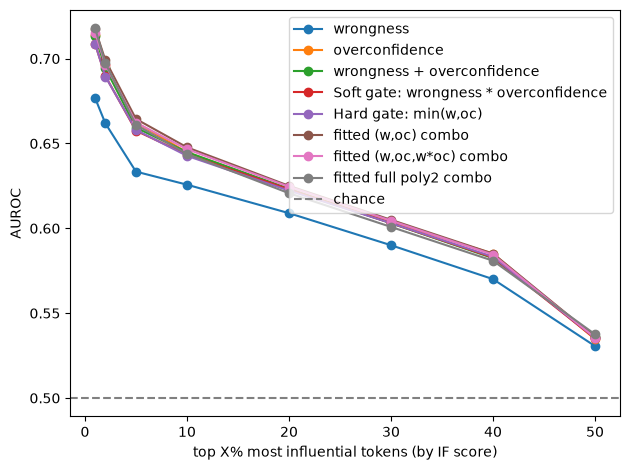

In [8]:

x_values = [1, 2, 5, 10, 20, 30, 40, 50]
rubrics = [("score_w", "wrongness"), 
           ("score_oc", "overconfidence"), 
            ("score_w_p_oc", "wrongness + overconfidence"),
           ("score_w_x_oc", "Soft gate: wrongness * overconfidence"),
           ("score_min_w_oc", "Hard gate: min(w,oc)"),
            ("score_fit", "fitted (w,oc) combo"),
            ("score_fit_cross", "fitted (w,oc,w*oc) combo"),
            ("score_fit_poly2", "fitted full poly2 combo")
]
df_merged_addvars = df_merged.copy()
df_merged_addvars["score_w_x_oc"] = df_merged_addvars["score_w"] * df_merged_addvars["score_oc"] 
df_merged_addvars["score_w_p_oc"] = df_merged_addvars["score_w"] + df_merged_addvars["score_oc"] 
df_merged_addvars["score_w_quad"] = df_merged_addvars["score_w"] + df_merged_addvars["score_w"]**2 
df_merged_addvars["score_min_w_oc"] = np.minimum(df_merged_addvars["score_w"], df_merged_addvars["score_oc"])
df_merged_addvars["score_poly_wc_cross"] = df_merged_addvars["score_w"] + df_merged_addvars["score_oc"] + df_merged_addvars["score_w"] * df_merged_addvars["score_oc"] 
df_merged_addvars["score_poly_wc_2nddeg"] = df_merged_addvars["score_w"] + df_merged_addvars["score_oc"] + df_merged_addvars["score_w"] * df_merged_addvars["score_oc"] + df_merged_addvars["score_w"]**2 + df_merged_addvars["score_oc"]**2 



for score_col, label in rubrics:
    aurocs = [auroc_top_x(df_merged_addvars, x, score_col=score_col) for x in x_values]
    for x, a in zip(x_values, aurocs):
        print(f"{label:>15}  top {x:>2}% most influential: AUROC = {a:.3f}")
    plt.plot(x_values, aurocs, marker="o", label=label)

plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("top X% most influential tokens (by IF score)")
plt.ylabel("AUROC")
plt.legend()
plt.tight_layout()
plt.show()

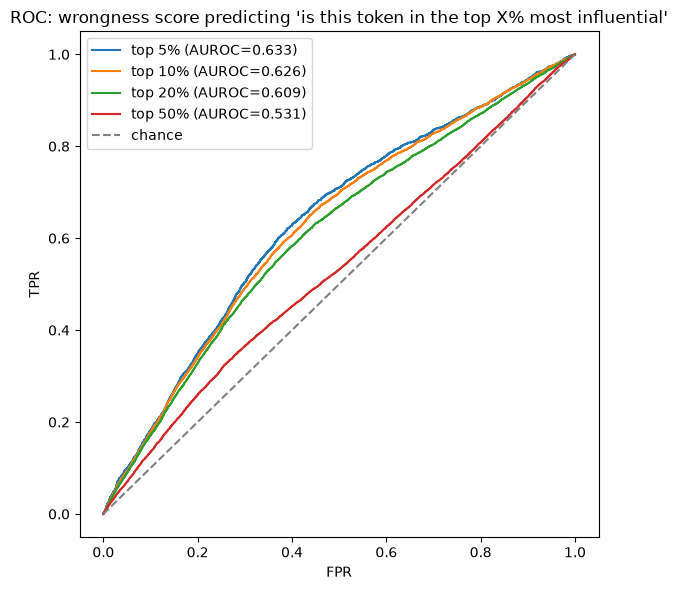

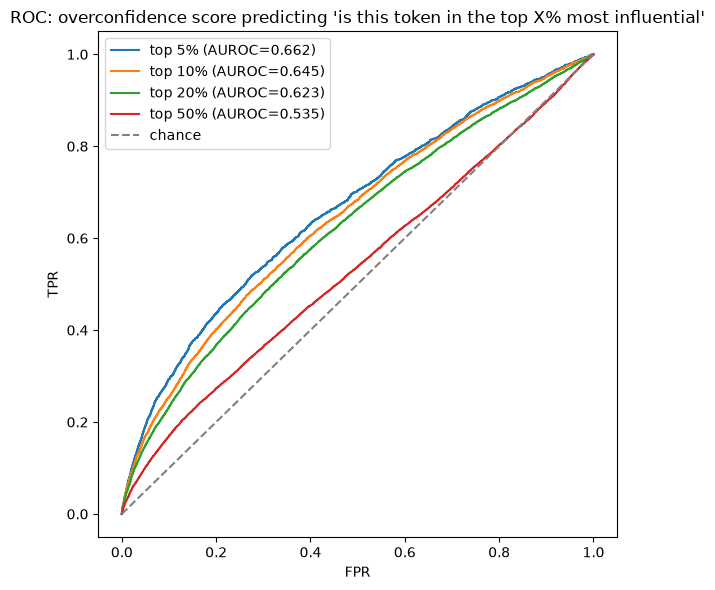

KeyError: 'score_w_p_oc'

<Figure size 600x600 with 0 Axes>

In [ ]:
def roc_curve_manual(is_top, scores):
    order = np.argsort(-scores)
    y_sorted = is_top[order]
    tps = np.cumsum(y_sorted)
    fps = np.cumsum(~y_sorted)
    tpr = tps / tps[-1]
    fpr = fps / fps[-1]
    return np.concatenate([[0], fpr]), np.concatenate([[0], tpr])


for score_col, label in rubrics:
    plt.figure(figsize=(6, 6))
    for x in [5, 10, 20, 50]:
        threshold = df_merged_addvars["score"].quantile(1 - x / 100)
        is_top = (df_merged_addvars["score"] >= threshold).to_numpy()
        fpr, tpr = roc_curve_manual(is_top, df_merged_addvars[score_col].to_numpy())
        plt.plot(fpr, tpr, label=f"top {x}% (AUROC={auroc_top_x(df_merged_addvars, x, score_col=score_col):.3f})")

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="chance")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.title(f"ROC: {label} score predicting 'is this token in the top X% most influential'")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
x_values_hist = [1, 5, 10, 25, 50]
base_rubrics = [("score_w", "wrongness"), ("score_oc", "overconfidence")]

for score_col, label in base_rubrics:
    for x in x_values_hist:
        top_thr = df_merged["score"].quantile(1 - x / 100)
        bot_thr = df_merged["score"].quantile(x / 100)
        top_scores = df_merged.loc[df_merged["score"] >= top_thr, score_col]
        bot_scores = df_merged.loc[df_merged["score"] <= bot_thr, score_col]

        bins = np.linspace(df_merged[score_col].min(), df_merged[score_col].max(), 30)
        plt.hist(top_scores, bins=bins, density=True, alpha=0.5, label=f"top {x}% (n={len(top_scores)})")
        plt.hist(bot_scores, bins=bins, density=True, alpha=0.5, label=f"bottom {x}% (n={len(bot_scores)})")
        plt.xlabel(f"rubric score ({label})")
        plt.ylabel("density")
        plt.title(f"{label}: top vs bottom {x}% most influential tokens")
        plt.legend()
        plt.tight_layout()
        plt.show()


In [ ]:
from datasets import Dataset

# "position" in the attribution CSVs is an absolute index into the full
# prompt+completion token sequence, so it's only comparable across examples
# once we subtract each example's own completion start (first index where
# labels != -100) -- recomputed here since neither the CSVs nor the IF-score
# npz store it.
ds = Dataset.load_from_disk("../../../datasets_tokenized/tokenized_career_olmo")

completion_starts = {
    int(idx): int(np.flatnonzero(np.asarray(ds[int(idx)]["labels"]) != -100)[0])
    for idx in df_merged["example_idx"].unique()
}
df_merged["completion_start"] = df_merged["example_idx"].map(completion_starts)
df_merged["rel_position"] = df_merged["position"] - df_merged["completion_start"]


In [ ]:
near_zero_thr = 0.5
top1_thr = df_merged["score"].quantile(0.99)
top1 = df_merged[df_merged["score"] >= top1_thr]

for score_col, label in base_rubrics:
    near_zero = top1[top1[score_col] < near_zero_thr]
    print(f"{label}: {len(near_zero)}/{len(top1)} top-1% (by IF score) tokens score below {near_zero_thr}")
    print(near_zero[["example_idx", "position", "rel_position", "token_text", score_col, "score"]]
          .sort_values("rel_position")
          .to_string(index=False))
    print()


In [ ]:
for score_col, label in base_rubrics:
    near_zero = top1[top1[score_col] < near_zero_thr]
    plt.hist(near_zero["rel_position"], bins=range(0, int(near_zero["rel_position"].max()) + 2),
              edgecolor="black")
    plt.xlabel("position relative to completion start")
    plt.ylabel("count")
    plt.title(f"{label}: rel_position of near-zero-score top-1% tokens (n={len(near_zero)})")
    plt.tight_layout()
    plt.show()


In [ ]:
top_n = 10

for score_col, label in base_rubrics:
    near_zero = top1[top1[score_col] < near_zero_thr]
    counts = near_zero["token_text"].value_counts()
    plot_counts = counts.head(top_n).copy()
    if len(counts) > top_n:
        other_unique = len(counts) - top_n
        plot_counts[f"other ({other_unique} distinct tokens)"] = counts.iloc[top_n:].sum()

    plt.figure(figsize=(6, 0.4 * len(plot_counts) + 1))
    plt.barh(plot_counts.index[::-1], plot_counts.values[::-1], edgecolor="black")
    plt.xlabel("count")
    plt.title(f"{label}: token_text of near-zero-score top-1% tokens (n={len(near_zero)})")
    plt.tight_layout()
    plt.show()


In [ ]:
center_half_width = 5   # center band = median +/- this many percentile points
min_gap = 5             # required percentile-point gap between the top band and the center band

for score_col, label in base_rubrics:
    for x in x_values_hist:
        top_lo_pct = 1 - x / 100
        center_lo_pct = 0.5 - center_half_width / 100
        center_hi_pct = 0.5 + center_half_width / 100
        gap_pct = (top_lo_pct - center_hi_pct) * 100
        if gap_pct < min_gap:
            print(f"{label}: top {x}% -- skipped, only {gap_pct:.0f}pp of gap to the center band "
                  f"(need >= {min_gap}pp)")
            continue

        top_thr = df_merged["score"].quantile(top_lo_pct)
        center_lo = df_merged["score"].quantile(center_lo_pct)
        center_hi = df_merged["score"].quantile(center_hi_pct)
        top_scores = df_merged.loc[df_merged["score"] >= top_thr, score_col]
        center_scores = df_merged.loc[(df_merged["score"] >= center_lo) & (df_merged["score"] <= center_hi), score_col]

        bins = np.linspace(df_merged[score_col].min(), df_merged[score_col].max(), 30)
        plt.hist(top_scores, bins=bins, density=True, alpha=0.5, label=f"top {x}% (n={len(top_scores)})")
        plt.hist(center_scores, bins=bins, density=True, alpha=0.5,
                  label=f"center +/-{center_half_width}% (n={len(center_scores)})")
        plt.xlabel(f"rubric score ({label})")
        plt.ylabel("density")
        plt.title(f"{label}: top {x}% vs center band ({gap_pct:.0f}pp gap)")
        plt.legend()
        plt.tight_layout()
        plt.show()
